<a href="https://colab.research.google.com/github/abdul-sgf3/RegresiLinear_Kelas5A_Kelompok_5/blob/main/RegresiLinear_5A_Kelompok1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Exploratory Data Analysis (EDA)**

In [ ]:
# 1. Install library kaggle (biasanya sudah ada di Colab, tapi untuk memastikan)
!pip install -q kaggle

In [ ]:
# 2. Mengatur Environment Variable untuk API Token
import os
import getpass

print("Silakan tempel (paste) API Token Kaggle Anda (dimulai dengan KGAT_...) dan tekan Enter:")
# getpass digunakan agar token yang Anda ketik tidak terlihat di layar
kaggle_token = getpass.getpass('KAGGLE_API_TOKEN: ')

# Menyetel environment variable agar library kaggle bisa membacanya
os.environ['KAGGLE_API_TOKEN'] = kaggle_token

print("\nOtentikasi API Kaggle Selesai!")

Silakan tempel (paste) API Token Kaggle Anda (dimulai dengan KGAT_...) dan tekan Enter:
KAGGLE_API_TOKEN: ··········

Otentikasi API Kaggle Selesai!


In [ ]:
# ---------------------------------------------------------
# 3. MENGUNDUH DATASET CONTOH
# Perintah: kaggle datasets download -d [nama-pemilik/nama-dataset]
# ---------------------------------------------------------
print("Mengunduh dataset Students Performance...")
!kaggle datasets download -d dansbecker/melbourne-housing-snapshot

Mengunduh dataset Students Performance...
Dataset URL: https://www.kaggle.com/datasets/dansbecker/melbourne-housing-snapshot
License(s): CC-BY-NC-SA-4.0
100% 451k/451k [00:00<00:00, 32.1MB/s]



In [ ]:
# 4. Mengekstrak file ZIP hasil unduhan
# -q artinya 'quiet' (tanpa log ekstraksi yang panjang)
!unzip -q melbourne-housing-snapshot.zip -d dataset_Melbourne_Housing_Snapshot/

print("Unduhan dan Ekstraksi Selesai!")

Unduhan dan Ekstraksi Selesai!


In [ ]:
# ---------------------------------------------------------
# 5. MEMUAT DATA KE PANDAS (Langkah Awal EDA)
# ---------------------------------------------------------
import pandas as pd

# Membaca file CSV yang sudah diekstrak
# Sesuaikan nama file CSV dengan isi dari ZIP tersebut
df = pd.read_csv('dataset_Melbourne_Housing_Snapshot/melb_data.csv')

In [ ]:
# Menampilkan 5 baris pertama untuk memastikan koneksi dan load data berhasil
print("\n--- 5 Baris Pertama Dataset Melbourne Housing Snapshot ---")
display(df.head())


--- 5 Baris Pertama Dataset Melbourne Housing Snapshot ---


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [ ]:
# Tampilkan 5 baris pertama data
print("--- 5 Baris Pertama Data ---")
display(df.head())

# Tampilkan 5 baris terakhir data (opsional, untuk memastikan data dimuat utuh)
print("\n--- 5 Baris Terakhir Data ---")
display(df.tail())

# Cek dimensi data (jumlah baris dan kolom)
print(f"\nDimensi dataset: {df.shape[0]} baris, {df.shape[1]} kolom")

# Cek tipe data setiap kolom dan informasi penggunaan memori
print("\n--- Informasi Dataset (Tipe Data & Non-Null) ---")
df.info()

# Dapatkan nama-nama kolom
print("\n--- Daftar Nama Kolom ---")
print(df.columns.tolist())

--- 5 Baris Pertama Data ---


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0



--- 5 Baris Terakhir Data ---


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
13575,Wheelers Hill,12 Strada Cr,4,h,1245000.0,S,Barry,26/08/2017,16.7,3150.0,4.0,2.0,2.0,652.0,NaN,1981.0,NaN,-37.90562,145.16761,South-Eastern Metropolitan,7392.0
13576,Williamstown,77 Merrett Dr,3,h,1031000.0,SP,Williams,26/08/2017,6.8,3016.0,3.0,2.0,2.0,333.0,133.0,1995.0,NaN,-37.85927,144.87904,Western Metropolitan,6380.0
13577,Williamstown,83 Power St,3,h,1170000.0,S,Raine,26/08/2017,6.8,3016.0,3.0,2.0,4.0,436.0,NaN,1997.0,NaN,-37.85274,144.88738,Western Metropolitan,6380.0
13578,Williamstown,96 Verdon St,4,h,2500000.0,PI,Sweeney,26/08/2017,6.8,3016.0,4.0,1.0,5.0,866.0,157.0,1920.0,NaN,-37.85908,144.89299,Western Metropolitan,6380.0
13579,Yarraville,6 Agnes St,4,h,1285000.0,SP,Village,26/08/2017,6.3,3013.0,4.0,1.0,1.0,362.0,112.0,1920.0,NaN,-37.81188,144.88449,Western Metropolitan,6543.0



Dimensi dataset: 13580 baris, 21 kolom

--- Informasi Dataset (Tipe Data & Non-Null) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13580 entries, 0 to 13579
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Suburb         13580 non-null  object 
 1   Address        13580 non-null  object 
 2   Rooms          13580 non-null  int64  
 3   Type           13580 non-null  object 
 4   Price          13580 non-null  float64
 5   Method         13580 non-null  object 
 6   SellerG        13580 non-null  object 
 7   Date           13580 non-null  object 
 8   Distance       13580 non-null  float64
 9   Postcode       13580 non-null  float64
 10  Bedroom2       13580 non-null  float64
 11  Bathroom       13580 non-null  float64
 12  Car            13518 non-null  float64
 13  Landsize       13580 non-null  float64
 14  BuildingArea   7130 non-null   float64
 15  YearBuilt      8205 non-null   float64
 16  Coun

--- Pengecekan Missing Values ---


,Jumlah Missing,Persentase (%)
Car,62,0.456554
BuildingArea,6450,47.496318
YearBuilt,5375,39.580265
CouncilArea,1369,10.081001


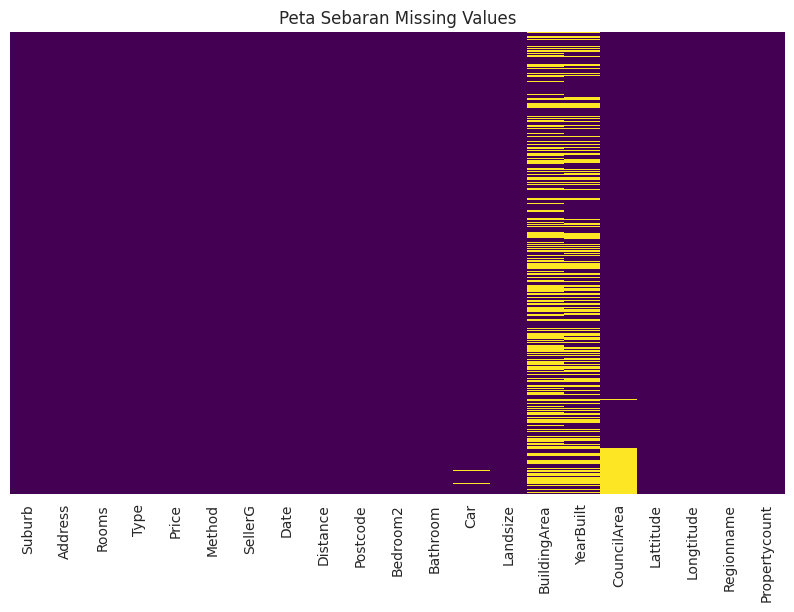


--- Pengecekan Data Duplikat ---
Jumlah baris duplikat identik: 0


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Pengecekan Missing Values ---")
missing_data = df.isnull().sum()
missing_percent = (df.isnull().sum() / len(df)) * 100
missing_table = pd.concat([missing_data, missing_percent], axis=1, keys=['Jumlah Missing', 'Persentase (%)'])
# Tampilkan hanya kolom yang memiliki missing value
display(missing_table[missing_table['Jumlah Missing'] > 0])

# Visualisasi Missing Values (Menggunakan Heatmap seaborn)
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), yticklabels=False, cbar=False, cmap='viridis')
plt.title('Peta Sebaran Missing Values')
plt.show()

print("\n--- Pengecekan Data Duplikat ---")
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat identik: {jumlah_duplikat}")
# Jika ada, Anda bisa menampilkan contoh duplikatnya dengan mengaktifkan baris di bawah:
# if jumlah_duplikat > 0:
#     display(df[df.duplicated(keep=False)].sort_values(by=list(df.columns)))

In [ ]:
print("--- Statistik Deskriptif untuk Kolom Numerik ---")
display(df.describe())

print("\n--- Statistik Deskriptif untuk Kolom Kategori (Objek) ---")
display(df.describe(include='object'))

--- Statistik Deskriptif untuk Kolom Numerik ---


,Rooms,Price,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount
count,13580.000000,1.358000e+04,13580.000000,13580.000000,13580.000000,13580.000000,13518.000000,13580.000000,7130.000000,8205.000000,13580.000000,13580.000000,13580.000000
mean,2.937997,1.075684e+06,10.137776,3105.301915,2.914728,1.534242,1.610075,558.416127,151.967650,1964.684217,-37.809203,144.995216,7454.417378
std,0.955748,6.393107e+05,5.868725,90.676964,0.965921,0.691712,0.962634,3990.669241,541.014538,37.273762,0.079260,0.103916,4378.581772
min,1.000000,8.500000e+04,0.000000,3000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1196.000000,-38.182550,144.431810,249.000000
25%,2.000000,6.500000e+05,6.100000,3044.000000,2.000000,1.000000,1.000000,177.000000,93.000000,1940.000000,-37.856822,144.929600,4380.000000
50%,3.000000,9.030000e+05,9.200000,3084.000000,3.000000,1.000000,2.000000,440.000000,126.000000,1970.000000,-37.802355,145.000100,6555.000000
75%,3.000000,1.330000e+06,13.000000,3148.000000,3.000000,2.000000,2.000000,651.000000,174.000000,1999.000000,-37.756400,145.058305,10331.000000
max,10.000000,9.000000e+06,48.100000,3977.000000,20.000000,8.000000,10.000000,433014.000000,44515.000000,2018.000000,-37.408530,145.526350,21650.000000



--- Statistik Deskriptif untuk Kolom Kategori (Objek) ---


,Suburb,Address,Type,Method,SellerG,Date,CouncilArea,Regionname
count,13580,13580,13580,13580,13580,13580,12211,13580
unique,314,13378,3,5,268,58,33,8
top,Reservoir,5 Margaret St,h,S,Nelson,27/05/2017,Moreland,Southern Metropolitan
freq,359,3,9449,9022,1565,473,1163,4695


**Preprocessing & Feature Engineering**

Langkah 1 Membuat Salinan Dataset

In [ ]:
data = df.copy()

print("Ukuran data awal:", data.shape)

Ukuran data awal: (13580, 21)


Langkah 2 Membersihkan Kolom Date

In [ ]:
data['Date'] = pd.to_datetime(
    data['Date'],
    dayfirst=True,
    errors='coerce'
)

data['SaleYear'] = data['Date'].dt.year
data['SaleMonth'] = data['Date'].dt.month

# Hapus Date asli
data = data.drop(columns=['Date'])

data[['SaleYear', 'SaleMonth']].head()

,SaleYear,SaleMonth
0,2016,12
1,2016,2
2,2017,3
3,2017,3
4,2016,6


Temuan:
Kolom Date sekarang telah diubah menjadi dua fitur numerik:

*   SaleYear
*   SaleMonth

Langkah 3-Memeriksa  Kolom YearBuilt

In [ ]:
print("YearBuilt minimum sebelum cleaning:",
      data['YearBuilt'].min())

print(
    "Jumlah YearBuilt < 1800:",
    (data['YearBuilt'] < 1800).sum()
)

YearBuilt minimum sebelum cleaning: 1196.0
Jumlah YearBuilt < 1800: 1


Temuan:
Terdapat nilai YearBuilt yang terlalu kecil sehingga lebih tepat dianggap sebagai data tidak valid daripada nilai tahun pembangunan yang sebenarnya.

Langkah 4-Mengubah Tahun Tidak Valid menjadi Missing

In [ ]:
data.loc[data['YearBuilt'] < 1800, 'YearBuilt'] = np.nan

print(
    "Jumlah missing YearBuilt setelah cleaning:",
    data['YearBuilt'].isna().sum()
)

Jumlah missing YearBuilt setelah cleaning: 5376


Temuan:
Nilai YearBuilt yang tidak masuk akal tidak langsung dihapus dari baris datanya.

Kita mengubahnya menjadi NaN, sehingga nanti dapat ditangani dengan imputasi.

Langkah 5-BuildingArea dan Landsize

In [ ]:
# BuildingArea = 0 dianggap sebagai nilai tidak tersedia
data.loc[data['BuildingArea'] <= 0, 'BuildingArea'] = np.nan

# Landsize = 0 dianggap sebagai nilai tidak tersedia
data.loc[data['Landsize'] <= 0, 'Landsize'] = np.nan

print("Missing BuildingArea:",
      data['BuildingArea'].isna().sum())

print("Missing Landsize:",
      data['Landsize'].isna().sum())

Missing BuildingArea: 6467
Missing Landsize: 1939


Temuan:
Untuk fitur luas tanah/bangunan, nilai 0 kurang masuk akal sebagai ukuran properti sehingga diperlakukan sebagai missing.

Langkah-6

In [ ]:
# Definisikan kolom numerik yang mau di-scaling
fitur_numerik = ['Rooms', 'Distance', 'Landsize', 'BuildingArea',
                 'YearBuilt', 'Bathroom', 'Car', 'Propertycount']

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Load dataset
df = pd.read_csv('melb_data (1).csv')
print("Shape awal:", df.shape)
df.head()

Shape awal: (13580, 21)


,Suburb,Address,Rooms,Type,Price,Method,SellerG,Date,Distance,Postcode,Bedroom2,Bathroom,Car,Landsize,BuildingArea,YearBuilt,CouncilArea,Lattitude,Longtitude,Regionname,Propertycount
0,Abbotsford,85 Turner St,2,h,1480000.0,S,Biggin,3/12/2016,2.5,3067.0,2.0,1.0,1.0,202.0,NaN,NaN,Yarra,-37.7996,144.9984,Northern Metropolitan,4019.0
1,Abbotsford,25 Bloomburg St,2,h,1035000.0,S,Biggin,4/02/2016,2.5,3067.0,2.0,1.0,0.0,156.0,79.0,1900.0,Yarra,-37.8079,144.9934,Northern Metropolitan,4019.0
2,Abbotsford,5 Charles St,3,h,1465000.0,SP,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,0.0,134.0,150.0,1900.0,Yarra,-37.8093,144.9944,Northern Metropolitan,4019.0
3,Abbotsford,40 Federation La,3,h,850000.0,PI,Biggin,4/03/2017,2.5,3067.0,3.0,2.0,1.0,94.0,NaN,NaN,Yarra,-37.7969,144.9969,Northern Metropolitan,4019.0
4,Abbotsford,55a Park St,4,h,1600000.0,VB,Nelson,4/06/2016,2.5,3067.0,3.0,1.0,2.0,120.0,142.0,2014.0,Yarra,-37.8072,144.9941,Northern Metropolitan,4019.0


In [ ]:
# Drop kolom yang tidak relevan
drop_cols = ['Suburb', 'Address', 'SellerG', 'Date', 'CouncilArea']
df = df.drop(columns=drop_cols)

# Drop baris yang Price kosong (target)
df = df.dropna(subset=['Price'])

# Isi missing value
df['BuildingArea'] = df['BuildingArea'].fillna(df['BuildingArea'].median())
df['YearBuilt']    = df['YearBuilt'].fillna(df['YearBuilt'].median())
df['Car']          = df['Car'].fillna(0)

print("Missing setelah cleaning:", df.isnull().sum().sum())
print("Shape:", df.shape)

Missing setelah cleaning: 0
Shape: (13580, 16)


In [ ]:
Q1 = df['Landsize'].quantile(0.25)
Q3 = df['Landsize'].quantile(0.75)
IQR = Q3 - Q1
df = df[(df['Landsize'] >= Q1 - 1.5*IQR) & (df['Landsize'] <= Q3 + 1.5*IQR)]
print("Shape setelah hapus outlier:", df.shape)

Shape setelah hapus outlier: (13212, 16)


In [ ]:
# Pisahkan target dulu
y = df['Price']
X = df.drop(columns=['Price'])

# One-Hot Encoding untuk kolom kategorikal
X_encoded = pd.get_dummies(X, columns=['Type', 'Method', 'Regionname'],
                           drop_first=True)

# Drop Postcode & Bedroom2 (duplikat dari Rooms)
X_encoded = X_encoded.drop(columns=['Postcode', 'Bedroom2'], errors='ignore')

# Pastikan tidak ada NaN
X_encoded = X_encoded.fillna(X_encoded.median(numeric_only=True))

print("=== X_encoded berhasil dibuat ===")
print("Shape X_encoded:", X_encoded.shape)
print("Shape y        :", y.shape)
print("\nKolom X_encoded:")
print(X_encoded.columns.tolist())

=== X_encoded berhasil dibuat ===
Shape X_encoded: (13212, 23)
Shape y        : (13212,)

Kolom X_encoded:
['Rooms', 'Distance', 'Bathroom', 'Car', 'Landsize', 'BuildingArea', 'YearBuilt', 'Lattitude', 'Longtitude', 'Propertycount', 'Type_t', 'Type_u', 'Method_S', 'Method_SA', 'Method_SP', 'Method_VB', 'Regionname_Eastern Victoria', 'Regionname_Northern Metropolitan', 'Regionname_Northern Victoria', 'Regionname_South-Eastern Metropolitan', 'Regionname_Southern Metropolitan', 'Regionname_Western Metropolitan', 'Regionname_Western Victoria']


In [ ]:
# === LANGKAH 4: Train-Test Split ===
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.3, random_state=42
)

X_train = X_train.copy()
X_test  = X_test.copy()

print("=== HASIL LANGKAH 4 ===")
print(f"X_train: {X_train.shape[0]} baris, {X_train.shape[1]} kolom")
print(f"X_test : {X_test.shape[0]} baris, {X_test.shape[1]} kolom")

=== HASIL LANGKAH 4 ===
X_train: 9248 baris, 23 kolom
X_test : 3964 baris, 23 kolom


In [ ]:
# === LANGKAH 5: Feature Scaling ===
fitur_numerik = ['Rooms', 'Distance', 'Landsize', 'BuildingArea',
                 'YearBuilt', 'Bathroom', 'Car', 'Propertycount']

# Cek kolom ada semua
missing = [c for c in fitur_numerik if c not in X_train.columns]
print("Kolom hilang:", missing)

# Konversi ke numeric & isi NaN
for col in fitur_numerik:
    X_train[col] = pd.to_numeric(X_train[col], errors='coerce')
    X_test[col]  = pd.to_numeric(X_test[col],  errors='coerce')

X_train[fitur_numerik] = X_train[fitur_numerik].fillna(
    X_train[fitur_numerik].median()
)
X_test[fitur_numerik] = X_test[fitur_numerik].fillna(
    X_train[fitur_numerik].median()
)

# Scaling
sc = StandardScaler()
X_train[fitur_numerik] = sc.fit_transform(X_train[fitur_numerik])
X_test[fitur_numerik]  = sc.transform(X_test[fitur_numerik])

print("Preprocessing selesai! Siap untuk pemodelan.")
display(X_train.head())

Kolom hilang: []
Preprocessing selesai! Siap untuk pemodelan.


,Rooms,Distance,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Lattitude,Longtitude,Propertycount,Type_t,Type_u,Method_S,Method_SA,Method_SP,Method_VB,Regionname_Eastern Victoria,Regionname_Northern Metropolitan,Regionname_Northern Victoria,Regionname_South-Eastern Metropolitan,Regionname_Southern Metropolitan,Regionname_Western Metropolitan,Regionname_Western Victoria
12118,-0.999391,-0.286954,-0.775446,-0.627440,-0.975324,-0.109519,0.125316,-37.72136,144.92932,0.005406,False,True,True,False,False,False,False,True,False,False,False,False,False
4478,0.055313,-0.808148,-0.775446,0.415249,-0.334593,-0.109519,0.125316,-37.77330,145.00780,0.888714,False,False,False,False,True,False,False,True,False,False,False,False,False
3014,1.110016,0.616449,2.158812,0.415249,0.991894,1.862304,1.652981,-37.94190,145.01520,-0.457083,False,False,True,False,False,False,False,False,False,False,True,False,False
578,0.055313,-0.078476,-0.775446,0.415249,1.487163,-0.109519,0.125316,-37.80370,145.06360,-0.405164,False,False,True,False,False,False,False,False,False,False,True,False,False
8199,0.055313,0.286360,0.691683,0.415249,-0.746739,0.307206,0.974019,-37.90340,145.04090,-0.884277,False,True,True,False,False,False,False,False,False,False,True,False,False


**Regresi Linear**

**Sel 1 — Import Library & Generate Data**

In [ ]:
# ============================================================
# LANGKAH 1: Menyiapkan pustaka & membangkitkan data
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Agar hasil reproducible
np.random.seed(42)

# Jumlah sampel
n = 200

# Membangkitkan fitur
luas  = np.random.randint(30, 150, n)          # luas tanah (m²)
kamar = np.random.randint(1, 5, n)             # jumlah kamar
jarak = np.random.uniform(1, 20, n).round(1)   # jarak ke pusat kota (km)

# Membangkitkan target (harga) dengan hubungan linear + noise
# Model sebenarnya: harga = 50 + 2.5*luas + 15*kamar - 3*jarak + noise
harga = (50 + 2.5 * luas + 15 * kamar - 3 * jarak
         + np.random.normal(0, 20, n)).round(1)

# Membuat DataFrame
df = pd.DataFrame({
    'luas' : luas,
    'kamar': kamar,
    'jarak': jarak,
    'harga': harga
})

print("=== 5 Baris Pertama Dataset ===")
print(df.head())
print("\n=== Informasi Dataset ===")
print(df.info())
print("\n=== Statistik Deskriptif ===")
print(df.describe())

=== 5 Baris Pertama Dataset ===
   luas  kamar  jarak  harga
0   132      1    6.4  367.6
1    81      4    6.8  311.8
2   122      3   10.2  371.5
3    44      3    9.5  181.9
4   136      3   19.9  348.5

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   luas    200 non-null    int64  
 1   kamar   200 non-null    int64  
 2   jarak   200 non-null    float64
 3   harga   200 non-null    float64
dtypes: float64(2), int64(2)
memory usage: 6.4 KB
None

=== Statistik Deskriptif ===
             luas       kamar       jarak       harga
count  200.000000  200.000000  200.000000  200.000000
mean    87.755000    2.625000   10.099500  277.846500
std     34.864057    1.162381    5.400172   92.086832
min     30.000000    1.000000    1.100000   91.400000
25%     58.000000    2.000000    5.800000  206.450000
50%     89.000000    3.000000   

Penjelasan:

luas, kamar, jarak → fitur (X)

harga → target (y) yang dibangkitkan dari rumus linear + noise

Koefisien sebenarnya: 2.5 (luas), 15 (kamar), -3 (jarak), intercept 50



**Sel 2 — Exploratory Data Analysis (EDA)**

=== Missing Values ===
luas     0
kamar    0
jarak    0
harga    0
dtype: int64

Jumlah duplikat: 0


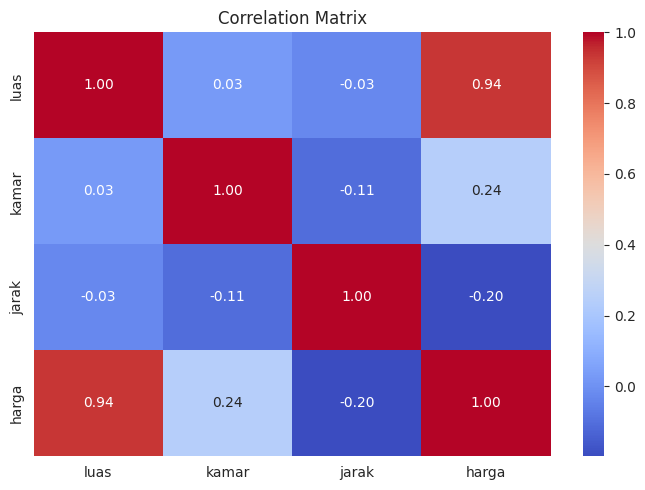

In [ ]:
# ============================================================
# LANGKAH 1b: EDA singkat
# ============================================================
import seaborn as sns

# Cek missing value
print("=== Missing Values ===")
print(df.isnull().sum())

# Cek duplikat
print("\nJumlah duplikat:", df.duplicated().sum())

# Heatmap korelasi
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

Penjelasan: luas dan kamar seharusnya berkorelasi positif dengan harga, sedangkan jarak berkorelasi negatif.

**Sel 3 — Pisahkan Fitur & Target, Lalu Split Data**

In [ ]:
# ============================================================
# LANGKAH 2: Membagi data & melatih model berganda
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# Pisahkan fitur (X) dan target (y)
X = df[['luas', 'kamar', 'jarak']]
y = df['harga']

# Split 80% train, 20% test
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Shape X_train:", X_tr.shape)
print("Shape X_test :", X_te.shape)
print("Shape y_train:", y_tr.shape)
print("Shape y_test :", y_te.shape)

Shape X_train: (160, 3)
Shape X_test : (40, 3)
Shape y_train: (160,)
Shape y_test : (40,)


Penjelasan:

random_state=42 → agar hasil konsisten setiap kali dijalankan

80% untuk training, 20% untuk testing **bold text**

**Sel 4 — Latih Model Regresi Linear**

In [ ]:
# ============================================================
# LANGKAH 2b: Latih model Linear Regression
# ============================================================
model = LinearRegression()
model.fit(X_tr, y_tr)

print("Model selesai dilatih.")

Model selesai dilatih.


**Penjelasan: model.fit() mencari koefisien (β) yang meminimalkan error kuadratik (Ordinary Least Squares).**

**Sel 5 — Baca Koefisien & Intercept**

In [ ]:
# ============================================================
# LANGKAH 3: Membaca koefisien & intercept
# ============================================================
print('Intercept:', round(model.intercept_, 3))
print('\nKoefisien tiap fitur:')
for nama, koef in zip(X.columns, model.coef_):
    print(f"{nama:<8}: {round(koef, 3)}")

Intercept: 47.985

Koefisien tiap fitur:
luas    : 2.471
kamar   : 15.609
jarak   : -2.696


Penjelasan & Interpretasi:

Intercept → nilai harga jika semua fitur = 0

Koefisien luas → setiap kenaikan 1 m², harga naik sebesar koefisien (idealnya ≈ 2.5)

Koefisien kamar → setiap tambahan 1 kamar, harga naik (idealnya ≈ 15)

Koefisien jarak → setiap tambahan 1 km, harga turun (idealnya ≈ -3)

**Sel 6 — Prediksi pada Data Uji**

In [ ]:
# ============================================================
# LANGKAH 4a: Prediksi pada data uji
# ============================================================
y_pred = model.predict(X_te)

# Bandingkan 10 prediksi pertama
hasil = pd.DataFrame({
    'Aktual'  : y_te.values[:10],
    'Prediksi': y_pred[:10].round(2)
})
print(hasil)

   Aktual  Prediksi
0   298.0    281.08
1   394.4    393.82
2   244.2    211.92
3   365.4    390.54
4   348.1    331.04
5   227.5    206.05
6   108.8    133.99
7   151.3    152.76
8   141.0    150.37
9   212.7    260.93


Penjelasan: Melihat seberapa dekat prediksi model dengan nilai aktual.

Sel 7 — Evaluasi Model (MSE, RMSE, MAE, R²)

In [ ]:
# ============================================================
# LANGKAH 4b: Evaluasi (MSE, RMSE, MAE, R2)
# ============================================================
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

mse  = mean_squared_error(y_te, y_pred)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(y_te, y_pred)
r2   = r2_score(y_te, y_pred)

print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAE  : {mae:.2f}")
print(f"R²   : {r2:.4f}")

MSE  : 306.37
RMSE : 17.50
MAE  : 13.93
R²   : 0.9607


Penjelasan Metrik:

Metrik	Arti
MSE	Rata-rata error kuadratik (sensitif terhadap outlier)
RMSE	Akar MSE → satuan sama dengan target (harga)
MAE	Rata-rata error absolut → lebih robust
R²	Proporsi variansi target yang dijelaskan model (0–1)
Target: R² mendekati 1.0 karena data dibangkitkan dari hubungan linear murni.

Sel 8 — Visualisasi: Actual vs Predicted

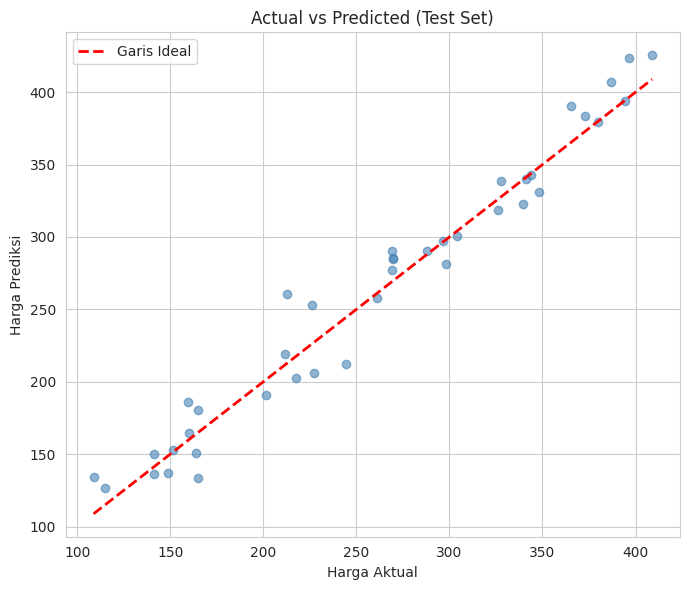

In [ ]:
# ============================================================
# LANGKAH 4c: Scatter Actual vs Predicted
# ============================================================
plt.figure(figsize=(7, 6))
plt.scatter(y_te, y_pred, alpha=0.6, color='steelblue')
plt.plot([y_te.min(), y_te.max()],
         [y_te.min(), y_te.max()],
         'r--', linewidth=2, label='Garis Ideal')
plt.xlabel('Harga Aktual')
plt.ylabel('Harga Prediksi')
plt.title('Actual vs Predicted (Test Set)')
plt.legend()
plt.tight_layout()
plt.show()

Penjelasan: Jika model bagus, titik-titik akan mendekati garis merah putus-putus (garis ideal y = x).



Sel 9 — Analisis Residual

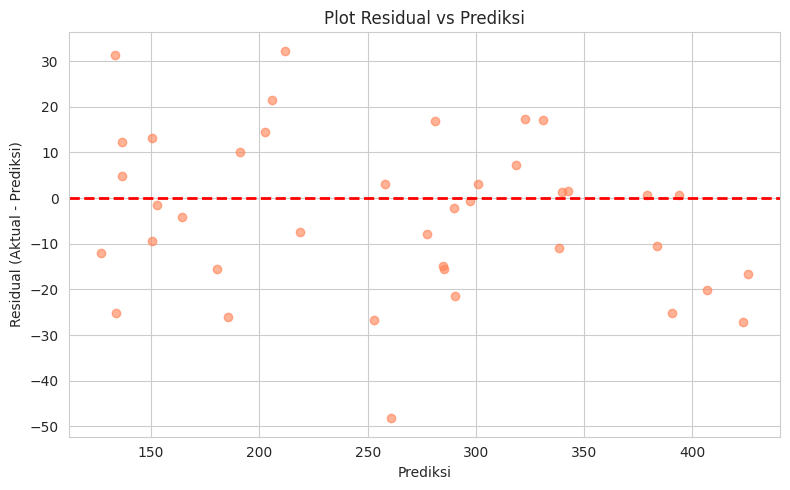

In [ ]:
# ============================================================
# LANGKAH 5: Analisis residual (galat)
# ============================================================
residual = y_te - y_pred

# Plot 1: Residual vs Prediksi
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residual, alpha=0.6, color='coral')
plt.axhline(0, color='red', ls='--', linewidth=2)
plt.xlabel('Prediksi')
plt.ylabel('Residual (Aktual - Prediksi)')
plt.title('Plot Residual vs Prediksi')
plt.tight_layout()
plt.show()

Penjelasan: Residual idealnya tersebar acak di sekitar 0. Jika ada pola (misal membentuk kurva), berarti ada hubungan non-linear yang belum tertangkap.

Sel 10 — Distribusi Residual

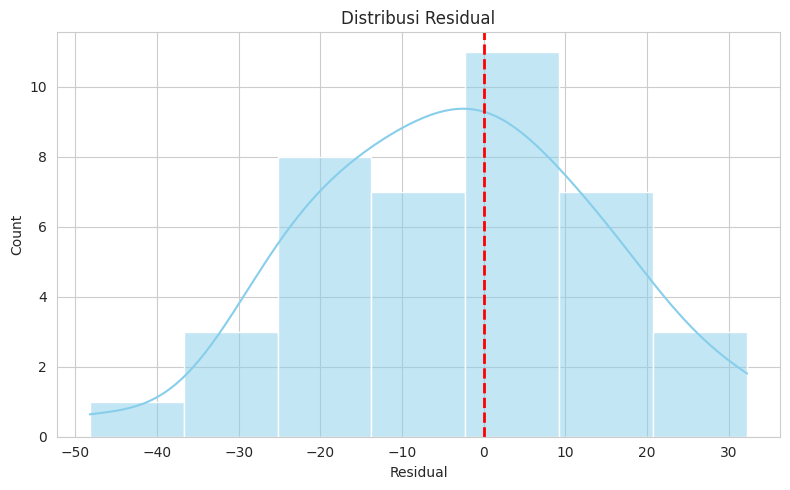

Mean residual : -3.5042
Std residual  : 17.3677


In [ ]:
# ============================================================
# LANGKAH 5b: Distribusi residual
# ============================================================
plt.figure(figsize=(8, 5))
sns.histplot(residual, kde=True, color='skyblue')
plt.axvline(0, color='red', ls='--', linewidth=2)
plt.xlabel('Residual')
plt.title('Distribusi Residual')
plt.tight_layout()
plt.show()

# Cek normalitas residual
print("Mean residual :", round(residual.mean(), 4))
print("Std residual  :", round(residual.std(), 4))

Penjelasan: Residual idealnya berdistribusi normal dengan mean ≈ 0. Ini memenuhi asumsi klasik regresi linear.

Sel 11 — Kesimpulan & Interpretasi

In [ ]:
# ============================================================
# LANGKAH 6: Kesimpulan
# ============================================================
print("=" * 55)
print("KESIMPULAN MODEL REGRESI LINEAR BERGANDA")
print("=" * 55)
print(f"Persamaan model:")
print(f"  harga = {model.intercept_:.2f}"
      f" + {model.coef_[0]:.2f}*luas"
      f" + {model.coef_[1]:.2f}*kamar"
      f" + {model.coef_[2]:.2f}*jarak")
print()
print(f"R²   = {r2:.4f}  → model menjelaskan {r2*100:.1f}% variansi harga")
print(f"RMSE = {rmse:.2f} → rata-rata error prediksi ± {rmse:.2f} satuan harga")
print()
print("Interpretasi koefisien:")
print(f"  - Setiap +1 m² luas  → harga {'naik' if model.coef_[0]>0 else 'turun'} "
      f"{abs(model.coef_[0]):.2f}")
print(f"  - Setiap +1 kamar    → harga {'naik' if model.coef_[1]>0 else 'turun'} "
      f"{abs(model.coef_[1]):.2f}")
print(f"  - Setiap +1 km jarak → harga {'naik' if model.coef_[2]>0 else 'turun'} "
      f"{abs(model.coef_[2]):.2f}")

KESIMPULAN MODEL REGRESI LINEAR BERGANDA
Persamaan model:
  harga = 47.99 + 2.47*luas + 15.61*kamar + -2.70*jarak

R²   = 0.9607  → model menjelaskan 96.1% variansi harga
RMSE = 17.50 → rata-rata error prediksi ± 17.50 satuan harga

Interpretasi koefisien:
  - Setiap +1 m² luas  → harga naik 2.47
  - Setiap +1 kamar    → harga naik 15.61
  - Setiap +1 km jarak → harga turun 2.70
